# 27 Swift/BAT: an independent check of the episodes and the precursors

19 of the 111 bursts of Zhu et al.'s sample are in the BAT GRB catalogue, and 18 of them have BAT event data (GRB 141102A was found only
in BAT's ground analysis, as a tentative detection, so no event file was kept). BAT is a coded-mask instrument: a pattern
of lead tiles casts a shadow on 32,768 CdZnTe detectors, and each photon is weighted by whether it could have come through the mask
from the burst's direction (mask weighting, `batmaskwtevt`), which takes the background out. The weighted rates have Gaussian errors,
not Poisson ones, so spectra are fitted with chi-squared and Bayesian blocks use the Gaussian fitness. The band is 15-150 keV, so most
main-emission E_peak lie above it and can only be limits.

The chain is the standard one (`instruments/swift_bat.py`, HEASoft's own tools; the BAT calibration database from HEASARC), and
`instruments/bat_compare.py` writes the three tables read here: the chain checked against the BAT GRB catalogue, the episodes from
BAT's light curve against ours from GBM, and BAT's spectrum of the precursor GBM defines. BAT times are put on GBM's axis with the
difference of the two trigger times and the light-travel time between the spacecraft, (r_Swift - r_Fermi) . n / c from Swift's orbit file
and GBM's trigdat file, which is up to about 45 ms and here between -0.5 and 28 ms: as long as some precursors.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
BAT = Path("results/bat")
FIGURES = Path("figures")
validation = pd.read_csv(BAT / "validation.csv")
episodes = pd.read_csv(BAT / "episodes_vs_gbm.csv")
precursors = pd.read_csv(BAT / "precursor_spectra.csv")
print(validation.burst.nunique(), "bursts checked against the catalogue;", episodes.burst.nunique(), "with episodes;",
      precursors.burst.nunique(), "with precursor spectra")

15 bursts checked against the catalogue; 19 with episodes; 19 with precursor spectra


## 1. The chain against the BAT catalogue

Power-law fits (15-150 keV) of the catalogue's two standard windows: the brightest second, and T100, the whole burst. The T100 window
of a long burst often runs through Swift's slew to the burst, during which the burst moves across BAT's field, so its response is the
average of responses made every 5 s, weighted by each slice's counts, as the catalogue does.

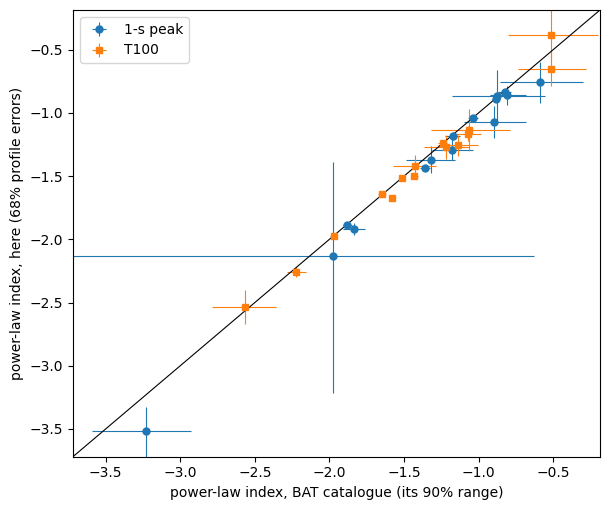

,burst,window,start,stop,index,index_minus,index_plus,catalogue_index,catalogue_low,catalogue_high,chi2,dof,catalogue_chi2,catalogue_dof,sigma
0,GRB211211A,1-s peak,6.864,7.864,-1.038,0.021,0.021,-1.036,-1.069,-1.002,57.403,56,58.33,57,-0.083
1,GRB211211A,T100,-0.004,120.712,-1.517,0.012,0.012,-1.515,-1.536,-1.495,28.886,56,29.53,57,-0.084
2,GRB190114C,1-s peak,0.232,1.232,-0.887,0.016,0.016,-0.886,-0.912,-0.859,33.593,56,33.63,57,-0.061
3,GRB190114C,T100,-6.604,703.192,-1.495,0.015,0.015,-1.431,-1.455,-1.406,73.004,56,90.47,57,-3.031
4,GRB180728A,1-s peak,12.612,13.612,-1.884,0.019,0.019,-1.879,-1.910,-1.848,40.737,56,42.73,57,-0.174
5,GRB180728A,T100,-0.244,36.512,-1.976,0.016,0.016,-1.972,-1.998,-1.946,43.214,56,44.77,57,-0.192
6,GRB161001A,1-s peak,1.368,2.368,-0.862,0.072,0.073,-0.806,-0.925,-0.684,36.950,56,38.47,57,-0.541
7,GRB161001A,T100,-0.216,3.104,-1.163,0.057,0.057,-1.073,-1.163,-0.982,55.887,56,56.46,57,-1.136
8,GRB090510,1-s peak,-0.316,0.684,-1.071,0.125,0.127,-0.895,-1.098,-0.682,56.145,56,46.16,57,-0.984
9,GRB090510,T100,-0.128,6.224,-1.138,0.163,0.166,-1.062,-1.321,-0.789,72.094,56,52.45,57,-0.326


In [2]:
v = validation.copy()
v["sigma"] = (v["index"] - v.catalogue_index) / np.hypot(0.5 * (v.index_minus + v.index_plus),
                                                         0.5 * (v.catalogue_high - v.catalogue_low) / 1.645)
fig, ax = plt.subplots(figsize=(6.2, 5.2))
for window, marker in (("1-s peak", "o"), ("T100", "s")):
    d = v[v.window == window]
    ax.errorbar(d.catalogue_index, d["index"], yerr=[d.index_minus, d.index_plus],
                xerr=[d.catalogue_index - d.catalogue_low, d.catalogue_high - d.catalogue_index], fmt=marker, ms=5, lw=0.8,
                label=window)
lims = [v[["index", "catalogue_index"]].min().min() - 0.2, v[["index", "catalogue_index"]].max().max() + 0.2]
ax.plot(lims, lims, color="k", lw=0.8)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("power-law index, BAT catalogue (its 90% range)")
ax.set_ylabel("power-law index, here (68% profile errors)")
ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "27_bat_validation.png", dpi=150); plt.show()
v[["burst", "window", "start", "stop", "index", "index_minus", "index_plus", "catalogue_index", "catalogue_low", "catalogue_high",
   "chi2", "dof", "catalogue_chi2", "catalogue_dof", "sigma"]].round(3)

24 of the 30 fits agree with the catalogue within 1 sigma and 27 within 2 sigma (the catalogue's 90% ranges converted to 68%, and our
errors from the profile of chi-squared). The three that don't are GRB 090618's two windows and GRB 190114C's T100, and they have one
thing in common: Swift's slew.

GRB 090618 shows where the difference is. The archive pipeline makes its own spectra before and after the slew, and ours on the same
windows are the same to the third decimal: -1.479 against -1.478 before it (-5.6 to 54.5 s) and -2.394 against -2.395 after it (120.5 to
219.7 s). So the extraction and the responses are right while the spacecraft is still. The catalogue's brightest second (65.4-66.4 s)
falls during the slew, where the catalogue makes responses its own way: ours gives -1.44 +/- 0.02 against its -1.36 (-1.40 to -1.33).
Making the mask weights with any of the three attitude files of the observation changes it by less than 0.002, so it isn't the attitude.
The T100 window runs through the slew (-1.67 against -1.58), and GRB 190114C's T100 is 703 s long with gaps in the event data
(-1.50 against -1.43). GRB 211211A's T100 also crosses its slew and agrees once the response is averaged over it (-1.517 against
-1.515). Why the slew-time spectra of GRB 090618 differ is unresolved. Two of the precursors below (GRB 190829A and 241030A) run into the slew, so their responses are averaged over it in the same way.

## 2. The episodes from BAT against those from GBM

Zhu et al.'s 2026 rule run on BAT's mask-weighted light curve (bins of the burst's GBM time resolution, but at least 16 ms, since at 4 ms
many BAT bins are empty), on GBM's time axis. Where BAT's event data have gaps, only the unbroken stretch around the main emission is used.

In [3]:
e = episodes.copy()
pivot = e.pivot_table(index="burst", columns="episode", values=["d_start", "d_stop"])
print(e.groupby("episode")[["d_start", "d_stop"]].agg(["count", "median"]).round(3).to_string())
e[["burst", "episode", "bat_pcode", "gbm_start", "gbm_stop", "bat_start", "bat_stop", "d_start", "d_stop", "offset_s", "light_travel_s",
   "bat_flags"]].round(3)

        d_start        d_stop       
          count median  count median
episode                             
me           16 -0.004     16  0.362
pe           12  0.004     12 -0.215
qe1          12 -0.215     12 -0.004


,burst,episode,bat_pcode,gbm_start,gbm_stop,bat_start,bat_stop,d_start,d_stop,offset_s,light_travel_s,bat_flags
0,090618A,pe,0.625,-0.632,34.088,-2.626,44.014,-1.994,9.926,3.198,0.006,emission_reaches_background
1,090618A,qe1,0.625,34.088,49.416,44.014,49.422,9.926,0.006,3.198,0.006,emission_reaches_background
2,090618A,me,0.625,49.416,99.144,49.422,99.390,0.006,0.246,3.198,0.006,emission_reaches_background
3,111228A,pe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no GBM episodes: the zhu batch has no episodes...
4,111228A,qe1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no GBM episodes: the zhu batch has no episodes...
5,111228A,me,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no GBM episodes: the zhu batch has no episodes...
6,190114C,pe,1.016,-5.712,-1.456,-5.820,-1.708,-0.108,-0.252,0.580,0.016,emission_reaches_background quiet_gaps_before_...
7,190114C,qe1,1.016,-1.456,-0.144,-1.708,-0.172,-0.252,-0.028,0.580,0.016,emission_reaches_background quiet_gaps_before_...
8,190114C,me,1.016,-0.144,12.752,-0.172,3.252,-0.028,-9.500,0.580,0.016,emission_reaches_background quiet_gaps_before_...
9,211211A,pe,0.217,-0.016,0.408,-0.010,0.230,0.006,-0.178,-0.010,0.007,emission_reaches_background


With the light-travel time put in, BAT's main emission starts where GBM's does: a median difference of 4 ms over the 16 bursts both
measure (BAT's bins are 16 ms), and within 0.05 s for 7 of them. The precursors start together too (a median of 4 ms over 12 bursts), but
in BAT the precursor ends earlier (by a median 0.2 s) and the main emission later (0.36 s): BAT's band is softer and narrower, so the faint
edges of each episode fall differently. The large differences (GRB 190727B, 241030A, 140323A, 231104A, 231214A) are long, structured
bursts that BAT's light curve splits into episodes differently, and the start of the main emission moves with the split. GRB 190829A gives
nothing: BAT saw it at 4% partial coding, with an unbroken stretch of event data of only 0.6 s around its main emission. GRB 111228A has
no GBM episodes and GRB 141102A no BAT data (its observation isn't in the archive; the catalogue lists it as a tentative ground detection).

## 3. The precursor's spectrum in BAT

BAT's spectrum of the precursor window GBM's rule defines, fitted with a power law and a Comptonized. An E_peak is quoted only if the
Comptonized puts it inside 15-150 keV with finite errors and gains more than 9 in chi-squared; otherwise the photon index says whether
the peak can lie inside the band (Sakamoto et al. 2009: for 1.3 < Gamma < 2.3 it can be anywhere from about 30 to 220 keV).

The comparison with GBM is made where BAT's band allows it: GBM's fit of the same window is folded through BAT's response and fitted with
a power law exactly as the data are, which gives the index BAT should measure if the two instruments agree. The fit used is GBM's
best-supported one (the lowest AIC = C + 2k among the Comptonized, Band and two-break model, whatever model the rule quotes an E_peak
from); the range covers every model within 10 in AIC of it (Burnham & Anderson 2002), and GBM's statistical spread comes from the 68%
corners of its Comptonized. The tension puts that and BAT's error together in quadrature. A precursor window longer than 5 s gets a
response averaged over 5 s slices, since some run into Swift's slew.

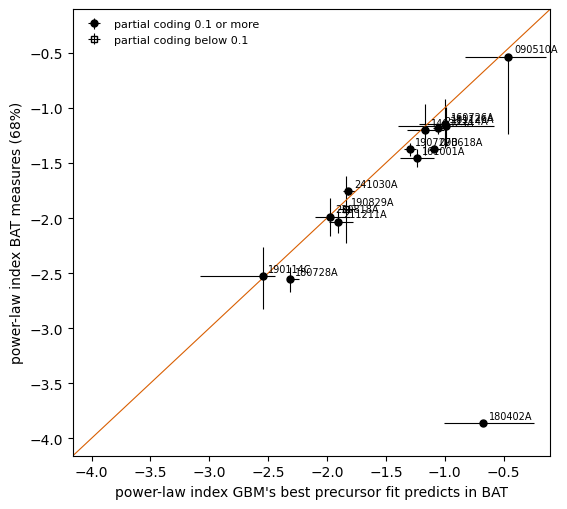

,burst,gbm_window,gbm_Ep,gbm_measured,bat_pcode,light_travel_s,bat_pl_index,bat_pl_minus,bat_pl_plus,from_gbm_model,bat_pl_index_from_gbm,from_gbm_all,from_gbm_stat,tension_sigma,bat_cpl_gain,bat_Ep,note,from_gbm_note
0,090618A,"[-0.632, 34.088]",261.118,True,0.625,0.005,-1.375,0.016,0.016,two-break,-1.094,Comptonized:-1.055 Band:-1.042 two-break:-1.094,0.037,5.858,22.869,NaN,E_peak not measured by BAT (its photon index a...,NaN
1,111228A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no GBM episodes: the zhu batch has no episodes...,NaN
2,190114C,"[-5.712, -1.456]",5.094,False,1.016,0.016,-2.529,0.297,0.264,Band,-2.547,Comptonized:-3.075 Band:-2.547 two-break:-2.437,NaN,NaN,-2.094,NaN,E_peak not measured by BAT (its photon index a...,"GBM doesn't measure the precursor's E_peak, so..."
3,211211A,"[-0.016, 0.408]",65.945,True,0.217,0.007,-2.032,0.101,0.098,Band,-1.908,Comptonized:-1.803 Band:-1.908 two-break:-1.880,0.073,0.937,-0.027,NaN,E_peak not measured by BAT (its photon index a...,NaN
4,231104A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no precursor in GBM under the zhu2026 rule,NaN
5,241030A,"[-1.072, 40.752]",76.784,True,0.805,0.001,-1.757,0.031,0.031,Band,-1.817,Comptonized:-1.786 Band:-1.817 two-break:-1.815,0.048,-1.024,9.860,84.169,E_peak measured by BAT,NaN
6,090510A,"[-0.024, 0.016]",355.157,True,0.162,0.004,-0.534,0.702,NaN,Band,-0.458,Comptonized:-0.634 Band:-0.458 two-break:-0.646,0.320,NaN,0.243,NaN,E_peak not measured by BAT (its photon index a...,NaN
7,111117A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no precursor in GBM under the zhu2026 rule,NaN
8,141102A,"[-0.064, 0.008]",487.733,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no BAT data: observation 00617316000 not found...,NaN
9,160726A,"[-0.032, 0.032]",209.175,True,0.586,0.007,-1.146,0.215,0.226,Band,-0.995,Comptonized:-1.013 Band:-0.995 two-break:-1.013,0.220,0.480,-0.001,NaN,E_peak not measured by BAT (its photon index a...,NaN


In [4]:
p = precursors.copy()
fit = p[p.bat_pl_index.notna() & p.bat_pl_index_from_gbm.notna()] if "bat_pl_index_from_gbm" in p else p.iloc[:0]
if len(fit):
    fig, ax = plt.subplots(figsize=(5.8, 5.2))
    low = fit.bat_pcode < 0.1
    for sel, marker, label in ((~low, "o", "partial coding 0.1 or more"), (low, "s", "partial coding below 0.1")):
        d = fit[sel]
        # x error: the spread over GBM's supported models and GBM's statistical spread, in quadrature
        stat = d.from_gbm_stat.fillna(0)                 # empty where GBM doesn't measure the precursor's E_peak (no tension then)
        ax.errorbar(d.bat_pl_index_from_gbm, d.bat_pl_index, yerr=[d.bat_pl_minus.fillna(0), d.bat_pl_plus.fillna(0)],
                    xerr=[np.hypot(d.bat_pl_index_from_gbm - d.from_gbm_low, stat),
                          np.hypot(d.from_gbm_high - d.bat_pl_index_from_gbm, stat)], fmt=marker, ms=5, lw=0.8,
                    color="k", mfc="k" if marker == "o" else "none", label=label)
        for r in d.itertuples():
            ax.annotate(r.burst, (r.bat_pl_index_from_gbm, r.bat_pl_index), xytext=(4, 3), textcoords="offset points", fontsize=7)
    lims = [min(fit.bat_pl_index.min(), fit.from_gbm_low.min()) - 0.3, max(fit.bat_pl_index.max(), fit.from_gbm_high.max()) + 0.3]
    ax.plot(lims, lims, color="#d95f02", lw=0.8)
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel("power-law index GBM's best precursor fit predicts in BAT")
    ax.set_ylabel("power-law index BAT measures (68%)")
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(FIGURES / "27_precursor_index.png", dpi=150); plt.show()
cols = ["burst", "gbm_window", "gbm_Ep", "gbm_measured", "bat_pcode", "light_travel_s", "bat_pl_index", "bat_pl_minus", "bat_pl_plus",
        "from_gbm_model", "bat_pl_index_from_gbm", "from_gbm_all", "from_gbm_stat", "tension_sigma", "bat_cpl_gain", "bat_Ep", "note",
        "from_gbm_note"]
p[[c for c in cols if c in p]].round(3)

Where both instruments measure a precursor, BAT's power-law index is what GBM's best-supported fit predicts in BAT's band for 10 of the
11 that give a tension (within 2 sigma, most within 1). For GRB 241030A BAT measures the peak itself: 84 (+17/-9) keV, against GBM's 77
(+6/-5) keV. GRB 190114C's and 180728A's precursors, which GBM can't measure (their peaks are near or below its band), are soft in BAT
(-2.53 and -2.56) as GBM's shapes predict, and 180728A's peak lies below BAT's band too.

The exception is GRB 090618's 35 s precursor: 5.9 sigma softer in BAT than any of GBM's three models predicts, and softer in every band,
above 30 and above 50 keV as well. BAT's spectra of this burst match the archive pipeline's, and GBM's fit rests on a single NaI (n4, 42
degrees from the burst), so I can't say which instrument is right. It is left open, as a caution on that collapsar's precursor E_peak.

## 4. What BAT adds, and what it can't

An independent instrument agrees with GBM wherever it can be compared: the BAT chain reproduces the archive pipeline exactly and the BAT
catalogue in 24 of 30 fits (the others all cross a slew); the episodes start at the same time once the light-travel time is in; and the
precursors' spectra in BAT's band are what GBM's fits predict for 10 of 11, with one peak measured directly that agrees. What BAT can't do
is measure the main emissions' E_peak, which lie above its band, or see bursts far off its axis well. The one real disagreement, GRB
090618's long precursor, is left open and flagged wherever that burst is used.